# Atividade Assíncrona 2 - Introdução ao Caos
## Theodoro Montoro 15489998

## Sobre os outros documentos


#### Para rodar esse código, é necessário pelo menos outros 2 documentos: o rossler.py e o rossler_cpp, onde estão definidas algumas poucas funções a respeito do sistema de Rossler, mas está feito lá todo o processo
#### para a integração em C++ (no caso, o rossler_cpp é o codigo em C++ do arquivo rossler.cpp já compilado), que é fortemente baseado no código da integração em C++ que vimos em sala. Se quiser rodar esse código localmente, é só baixar todos essas arquivos, presentes na pasta https://github.com/TheodoroMontoro/IntroCaosTheodoroMontoro/tree/main/Assíncrona%202 do meu github. Mas acredito que é possível rodar tudo no colab tranquilamente do jeito que fiz o código (clonando o repositório).

### Para figuras iterativas, rode o primeiro código se for um ambiente local e os outros dois se pelo colab

In [ ]:

# rode para ter as figuras iterativas, se já estiver o ambiente baixado localmente

%matplotlib widget



In [ ]:
# Rode para figuras iterativas se no ambiente do colab

!pip install -q ipympl
import os
os.kill(os.getpid(), 9)

In [ ]:
from google.colab import output
output.enable_custom_widget_manager()
%matplotlib widget

# Simulação e Diagrama de Bifurcação do Sistema de rossler para cs variados usando integração com C++

#### O módulo para a interface entre o Python e o C++ já foi criado e o código compilado, tudo já no github. O notebook "rossler" consegue, localmente, fazer a integração do sistema em C++

#### Clonando o repositório, deve ter acesso a tudo já necessário se pelo colab

In [ ]:


# Imports para fazer



# Clona o repositório que vai precisar se estiver no colab
if 'google.colab' in sys.modules:
    if not os.path.exists('/content/caos_functions'):
        !git clone -q https://github.com/TheodoroMontoro/IntroCaosTheodoroMontoro/Assíncrona 2.git



# Se estiver rodando localmente após baixar os arquivos da pasta Assíncrona 2, já deve funcionar
import sys
import os
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.integrate import solve_ivp
from scipy.interpolate import CubicSpline



from rossler import simulaRosslerCPP

In [ ]:

# Aqui estão definidas algumas funções que não foram definidas no rossler.py , onde o foco é o integrador pro diagrama de bifurcação, que foi adaptado para o sistema de Rossler.


# Configurações usadas para a maioria das simulações. Só não é utilizada para o cáluclo do maior Lyapunov pro caso caótico, em que é necessário um atol e rtol menores.
options = dict(atol=1e-10, rtol=1e-7, dense_output=False, method='DOP853')
np.random.seed(15489998) #nUSP para random seed


  # define o sistema de Rossler, para ser utilizado na função que o simula
def rosslerMapa(t, r, a =0.1, b=0.1, c=11.):
  x, y, z = r
  return np.array([
       (-y - z),
      x + a*y,
      b + (x - c) * z
      ])


  # define o evento de X máximo
def eventoXMaximo(t, r, a =0.1, b=0.1, c=11.):
    return rosslerMapa(t,r,a=a, b=b, c=c)[0]
eventoXMaximo.direction = -1


  # Função que simula o sistema de Rossler, a partir do solve_ivp. Configurações de transiente já são especificados nos parametros
  # Já é feito também uma segunda trajetória, para ser usada no cálculo do Lyapunov. A distância (dist0), após o transiente, é parâmetro
def simularosslerIVP(a =0.1, b=0.1, c=11., tTransiente=100, tSpan=10_000, nMax=500, r0=None, options=options, dist0=1e-5):
  eventoXMaximo.terminal = nMax
  if r0 is None:
    r0 = np.random.randn(3)
  solTransiente = solve_ivp(rosslerMapa, y0=r0, t_span=[0, tTransiente], args=(a,b,c,), **options)
  r1 = solTransiente.y[:,-1]
  sol = solve_ivp(rosslerMapa, y0=r1, t_span=[0, tSpan], events=eventoXMaximo, args=(a,b,c,), **options)


  rF = sol.y[:,-1]
  max = sol.y_events[0]

  
  u = np.random.randn(3)
  dr = dist0 * u/np.sqrt(np.sum(u**2))
  sollinha = solve_ivp(rosslerMapa, y0=r1+dr, t_span=[0, tSpan], events=eventoXMaximo, args=(a,b,c,), **options)

  return rF, max, sol, sollinha

# retorna a posição final, o array dos X_maximos e, mais importante, os arrays da trajetória r (argumento [2]) e rlinha (argumento [3])

# Exercícios

## a)


#### Séries temporais e figura 3d do atrator no caso de caótico

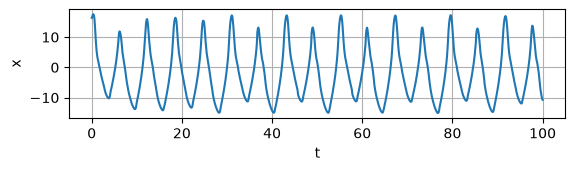

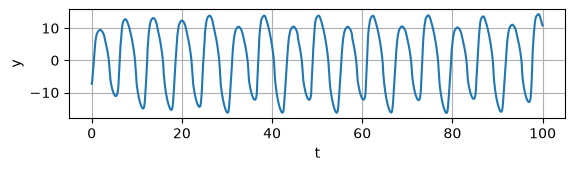

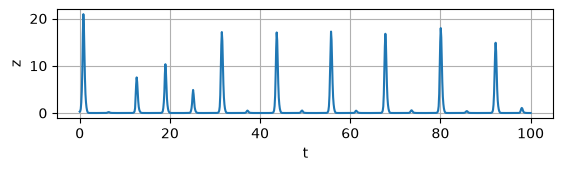

In [5]:
# Séries temporais

r0 = np.random.randn(3) # r0 randomizado
NOMEs = ['x', 'y', 'z']
t_span = [0,100]
c = 11.0

#simulação de com t_span de 100 e transiente de 1_000
Sol = simularosslerIVP(a =0.1, b=0.1, c=c, tTransiente=1_000, tSpan=100, nMax=500, r0=r0, options=options)
r = Sol[2].y

t = np.linspace( 0, t_span[-1], r.shape[1]) # acertando o tamanho do array temporal para a plotagem

for i in range(3):
  plt.figure()
  plt.subplot(3,1,i+1)
  plt.plot( t, r[i] )
  plt.grid()
  plt.ylabel( NOMEs[i] )
  plt.xlabel( 't' )
  plt.show()

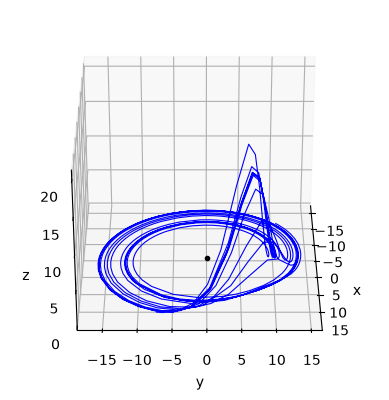

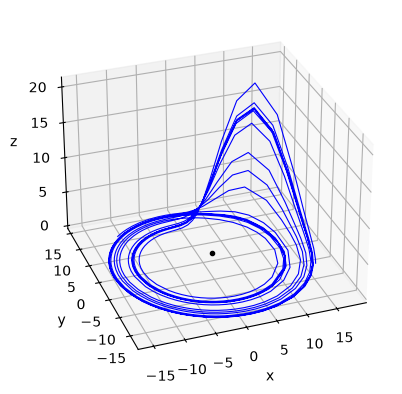

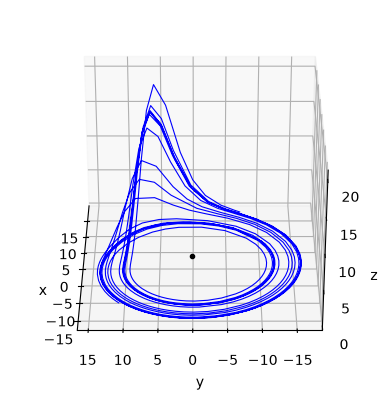

In [ ]:
# Vizualização do atrator caótico em c=11


for azim in [0,250,180]: # angulos para a visualização do atrator caótico
    plt.figure()
    ax3d = plt.gcf().add_subplot( projection='3d' ) # plotagem 3d
    ax3d.plot( r[0], r[1], r[2], '-', lw=0.8, alpha = 1.0, color = 'blue' )
    ax3d.plot( r0[0], r0[1], r0[2], '.k' )
    ax3d.set_xlabel( NOMEs[0] )
    ax3d.set_ylabel( NOMEs[1] )
    ax3d.set_zlabel( NOMEs[2] )
    ax3d.grid()
    ax3d.view_init(elev=30, azim=azim)
    plt.show()

## a.1)

#### Plotagem do Mapa de Lorenz do sistema de Rossler


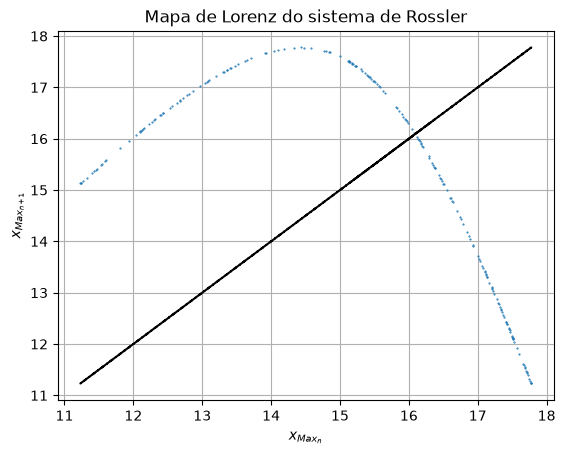

In [ ]:
# Mapa de Lorenz


r0 = np.random.randn(3)

tSpan = 3_000 # tempo maior, para melhor visualização do mapa de lorenz. 
# Imagem muito fraca se for usado um tSpan menor, como é feito na maioria dos outros itens


Sol = simularosslerIVP(a =0.1, b=0.1, c=11., tTransiente=1_000, tSpan=3_000, nMax=200, r0=r0, options=options)
xMax = Sol[2].y_events[0][:,0] 



plt.plot( xMax[:-1], xMax[1:], '.', ms=1 )
plt.plot( xMax, xMax, '--k' )
plt.xlabel( r'$x_{Max_{n}}$' )
plt.ylabel( r'$x_{Max_{n+1}}$' )
plt.title('Mapa de Lorenz do sistema de Rossler')
plt.grid()
plt.show()


# b) 

#### Integração e diagrama de bifurcação

In [ ]:
# Montagem do diagrama

cI = 2.01 
cF = cI + 18
cStep = 0.005
cs = np.arange(cI,cF+0.5*cStep, cStep) # montando o array dos valores de c, com passo de 0.005


r0 = np.random.randn(3)
tTransiente = 5_000
tSpan = 10_000
nMax = 1_000

paramsCPP = dict(r0=r0, tTransiente=tTransiente, tSpan=tSpan, # Parâmetros da Integração
                 a = 0.1, b = 0.1, # Parâmetros do Sistema
                 varNum="z`", dir=-1, crossVal=0, maxCross=nMax, # Parâmetros dos Eventos
                 rtol=options['rtol'], atol=options['atol']) # Parâmetros do Integrador




t0 = time.time()
j = 0
xMax = []
rEv = []
nCPP = len(cs)
for i, c in enumerate(cs):
    Sol = simulaRosslerCPP(c=c, dense_output=False, trajectory=False, **paramsCPP)
    rEvent = Sol.y_events
    # Printa a cada 20% das integrações
    if 100 * i / nCPP >= j * 20 or i == nCPP-1:
        t2 = time.time()
        print(f"[{j*20}% ({i+1} cs)] c = {c:g} | t = {t2-t0:.3g}s")
        j+=1
    rEv.append(rEvent)
    xMax.append(rEvent[2])
t1 = time.time()
print(f"\nC++ Serial ({len(cs)} cs): {t1-t0:.1f}s\n") # printa o tempo necessário para a integração, assim como vimos para o sistema de Lorenz

#np.savez(f'15489998_{cs[0]:g}', nUSP=15489998, cs=cs, xMax=xMax, rMax=rEv) --> Se quiser salvar o array do diagrama


# Aqui que pode demorar se estiver rodando no colab; localmente, dura por volta de 1 minuto.

[0% (1 cs)] c = 2.01 | t = 0.015s
[20% (722 cs)] c = 5.615 | t = 8.11s
[40% (1442 cs)] c = 9.215 | t = 18.6s
[60% (2162 cs)] c = 12.815 | t = 32.1s
[80% (2882 cs)] c = 16.415 | t = 46.1s
[100% (3601 cs)] c = 20.01 | t = 62.1s

C++ Serial (3601 cs): 62.1s



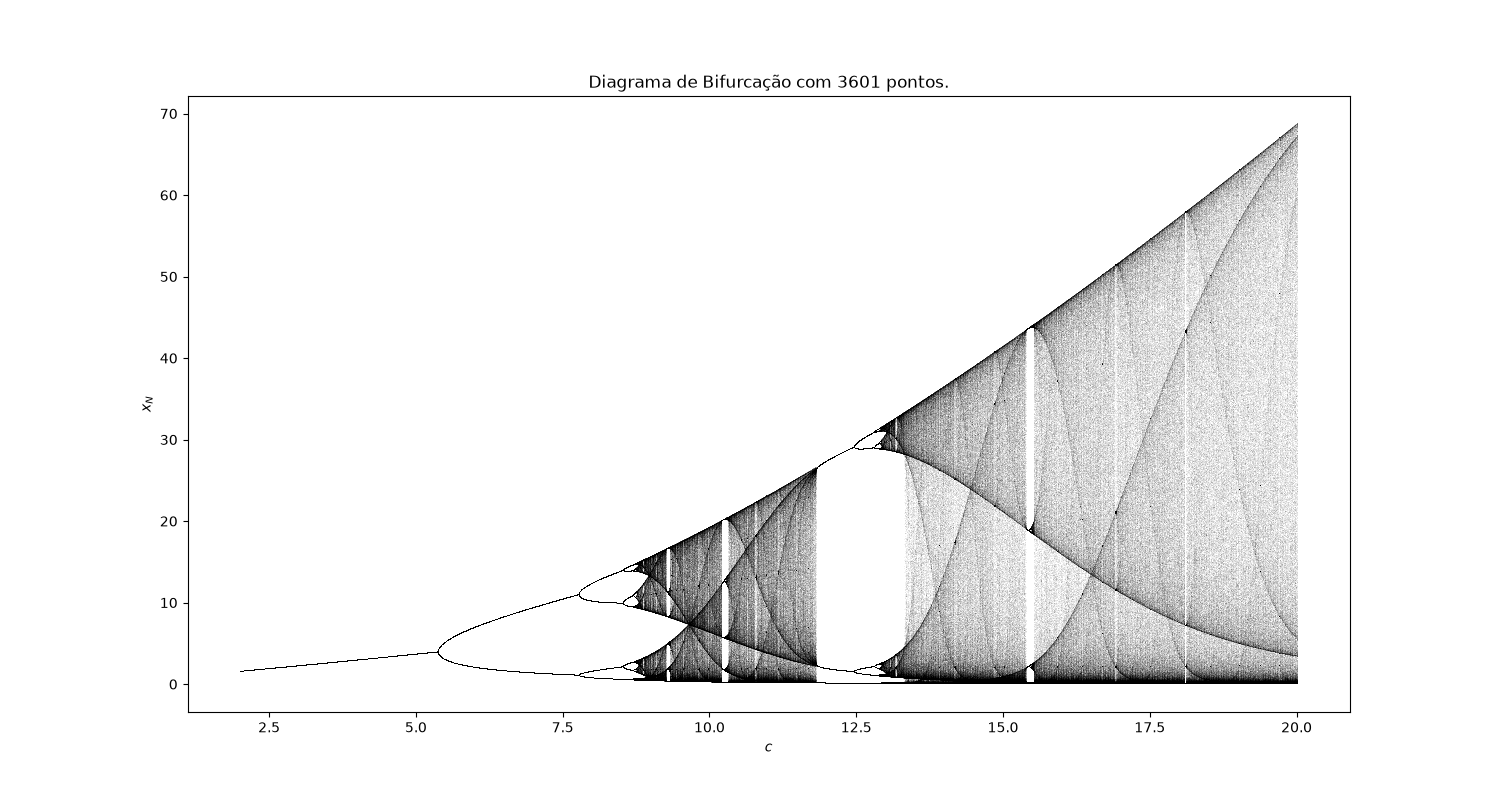

In [ ]:
# Plot do diagrama de bifurcações
plt.close("all")
plt.figure(figsize = (15,8))
for c, xM in zip(cs, xMax):
  plt.plot(c*np.ones_like(xM), xM, ',k', alpha=0.05)
plt.xlabel(r"$c$")
plt.ylabel(f"$x_N$")
plt.title(f"Diagrama de Bifurcação com {len(cs)} pontos.")
plt.show()

# c) 

### Cascata de duplicações e atratores periodicos

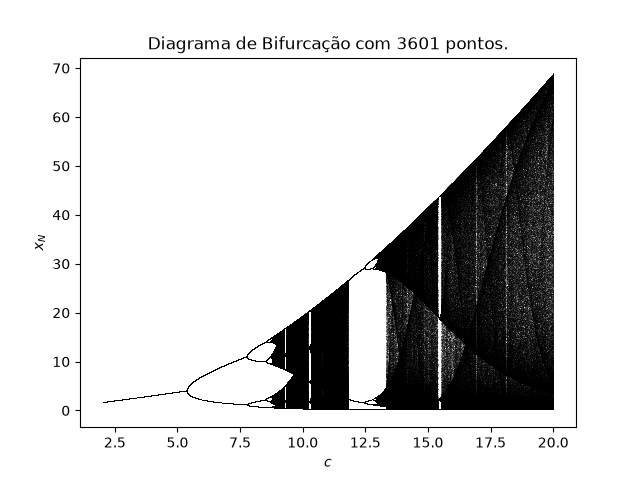

In [ ]:
# IMAGEM INTERATIVA para mostrar a duplicação de período; output não fica, mas imagem esta no pdf
plt.close("all")
plt.figure()
for c, xM in zip(cs, xMax):
  plt.plot(c*np.ones_like(xM), xM, ',k', alpha=0.05)
plt.xlabel(r"$c$")
plt.ylabel(f"$x_N$")
plt.title(f"Diagrama de Bifurcação com {len(cs)} pontos.")
plt.show()

c = 4.5


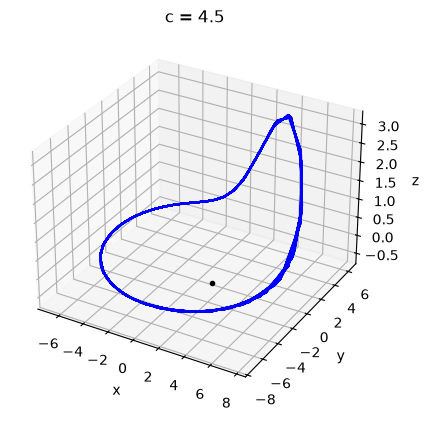

c = 6.5


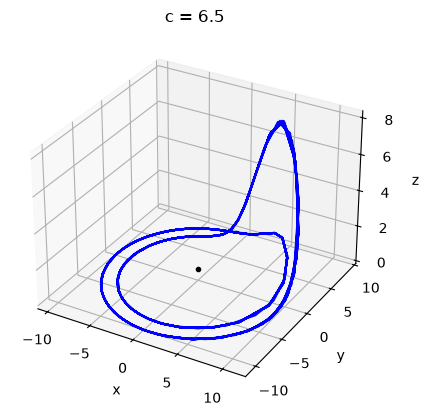

c = 8.0


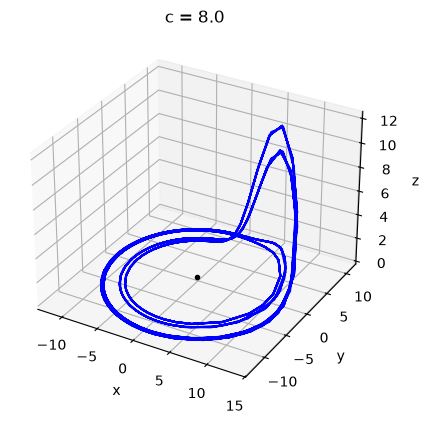

In [ ]:
# Figuras 3D dos atratores periódicos

plt.close( 'all' )



NOMEs = ['x', 'y', 'z']

cs = [4.5,6.5,8.0]

for c in cs:

    r0 = np.random.randn(3)
    Sol = simularosslerIVP(a =0.1, b=0.1, c=c, tTransiente=1_000, tSpan=100, nMax=500, r0=r0, options=options)
    r = Sol[2].y


    print(f'c = {c:.1f}')


    plt.figure()
    ax3d = plt.gcf().add_subplot( projection='3d' )
    ax3d.plot( r[0], r[1], r[2], '-', color = 'blue')
    ax3d.plot( r0[0], r0[1], r0[2], '.k' )
    ax3d.set_xlabel( NOMEs[0] )
    ax3d.set_ylabel( NOMEs[1] )
    ax3d.set_zlabel( NOMEs[2] )
    plt.title(f'c = {c}')
    ax3d.grid()
    plt.show()

c = 4.5


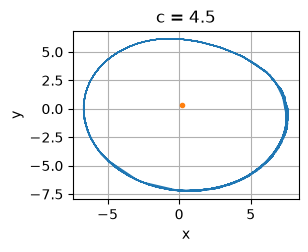

c = 6.5


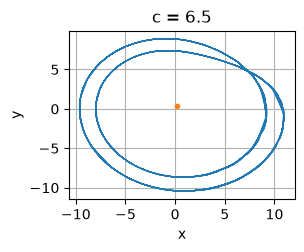

c = 8.0


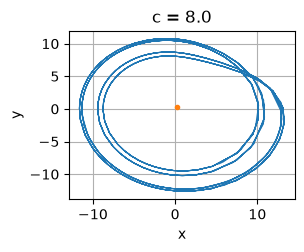

In [ ]:
# para melhor visualização da periodicidade específica, o gráfico xy é bom

r0 = np.random.randn(3)

NOMEs = ['x', 'y', 'z']

# c = 8.0 mostra bem o período 4
cs = [4.5,6.5,8.0]
for c in cs:
  Sol = simularosslerIVP(a =0.1, b=0.1, c=c, tTransiente=1_000, tSpan=100, nMax=500, r0=r0, options=options)
  r = Sol[2].y

  print(f'c = {c:.1f}')

  plt.figure()
  i = 0
  for i1 in range(2):
    for i2 in range(i1+1,2):
      i += 1
      plt.subplot(2,2,i)
      plt.plot( r[i1], r[i2], '-', lw=0.8 )
      plt.plot( r0[i1], r0[i2], '.' )
      plt.grid()
      plt.xlabel( NOMEs[i1] )
      plt.ylabel( NOMEs[i2] )
      plt.title(f'c = {c}')
      
  plt.show()

# d) 

####  Janelas periódicas, atrator de período 3 e atratores caóticos próximos da janela

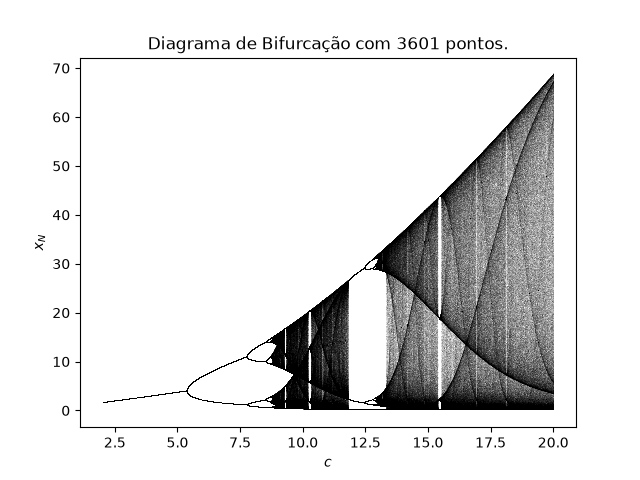

In [ ]:
# Imagem interativa da janela periódica no meio do mar de caos

plt.close("all")
plt.figure()
for c, xM in zip(cs, xMax):
  plt.plot(c*np.ones_like(xM), xM, ',k', alpha=0.05)
plt.xlabel(r"$c$")
plt.ylabel(f"$x_N$")
plt.title(f"Diagrama de Bifurcação com {len(cs)} pontos.")
plt.show()

c = 12.0


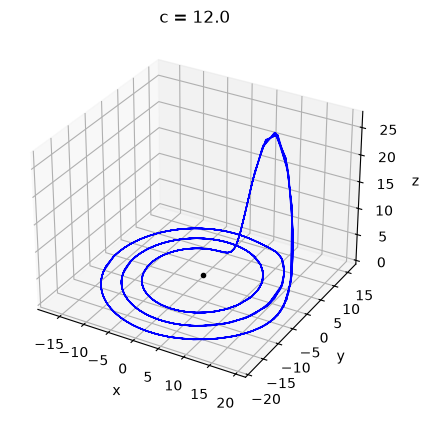

c = 11.8


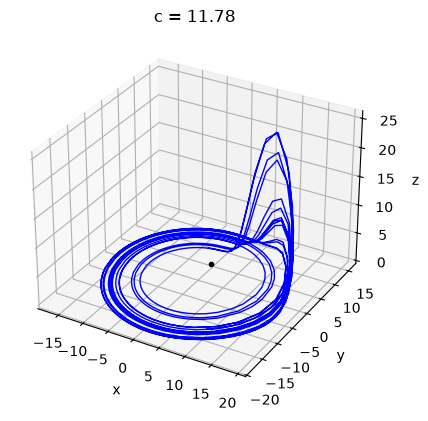

In [ ]:
# Figuras 3D do atrator de período 3 e do atrator caótico proximo a janela de estabilidade

plt.close( 'all' )

NOMEs = ['x', 'y', 'z']

cs = [12., 11.78] # c = 11.78 pertence a região caótica, mas já é proximo o suficiente de 12 para ser interessante

for c in cs:

    r0 = np.random.randn(3)
    Sol = simularosslerIVP(a =0.1, b=0.1, c=c, tTransiente=1_000, tSpan=100, nMax=500, r0=r0, options=options)
    r = Sol[2].y


    print(f'c = {c:.1f}')


    plt.figure()
    ax3d = plt.gcf().add_subplot( projection='3d' )
    ax3d.plot( r[0], r[1], r[2], '-', lw=1.0, alpha = 1.0, color = 'blue' )
    ax3d.plot( r0[0], r0[1], r0[2], '.k' )
    ax3d.set_xlabel( NOMEs[0] )
    ax3d.set_ylabel( NOMEs[1] )
    ax3d.set_zlabel( NOMEs[2] )
    ax3d.grid()
    plt.title(f'c = {c}')
    plt.show()
    
        


# e)

#### Sensibilidade as condições iniciais e maiores exponentes de Lyapunov

c = 4.5


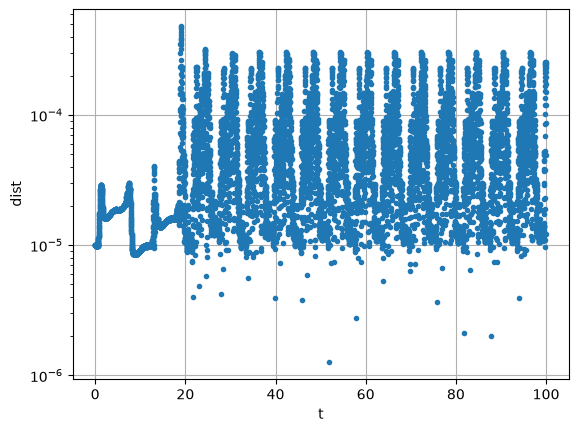

lambda_1 = 0.00020530635071150933
c = 6.5


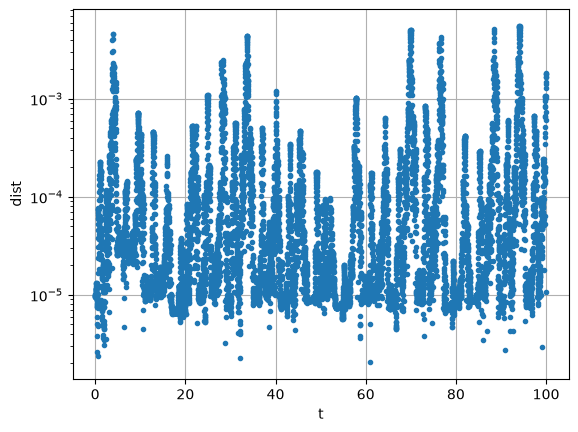

lambda_1 = 0.003772474434072573
c = 8.0


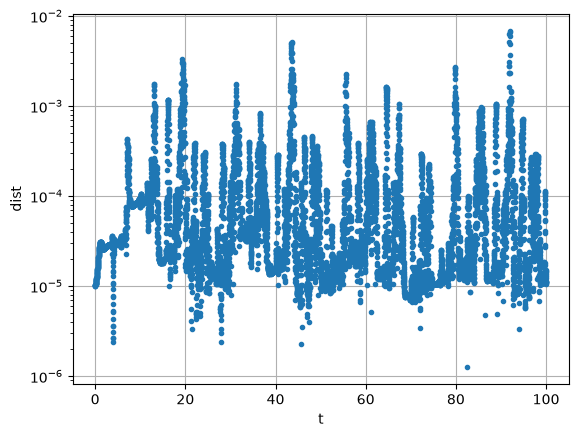

lambda_1 = -0.008310647414183829
c = 12.0


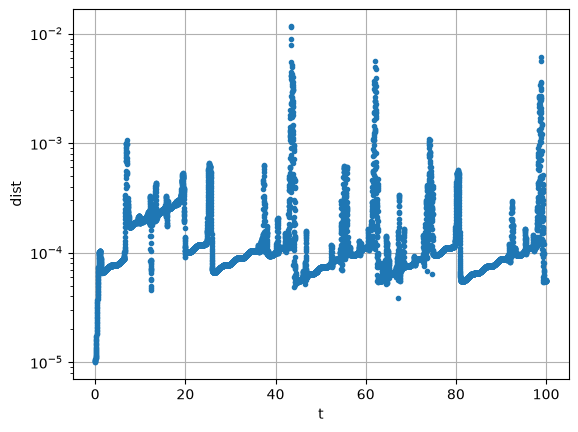

lambda_1 = -0.0010566441159883598


In [82]:
# Lyapunov nos casos periódicos

# atol e rtol um pouco menores, mas não precisa ser muito, visto que a distância inicial é de 1e-5
OPCOES = dict(  dense_output=True, method = 'DOP853', \
               atol=1e-9, rtol=1e-8 )
r0 = np.random.randn(3)
cs = [4.5,6.5,8.0,12.0]

for c in cs:
    print(f'c = {c:.1f}')

    
    dist0 = 1e-5

    Sol = simularosslerIVP(a =0.1, b=0.1, c=c, tTransiente=10_000, tSpan=100, nMax=500, r0=r0, options=OPCOES, dist0=dist0)
    r = Sol[2].y
    rlinha = Sol[3].y

    t0, t1 = Sol[2].t, Sol[3].t

   
    tmin = max(t0[0], t1[0])
    tmax = min(t0[-1], t1[-1])
    t = np.linspace(tmin, tmax, 10_001)

    r      = CubicSpline(t0, r,      axis=1)(t) # Interpolação para termos a mesma quantidade de pontos em r e rlinha, pois
    rlinha = CubicSpline(t1, rlinha, axis=1)(t) # a integração pelo método DOP853 acaba gerando uma quantidade diferente de pontos

    dist = np.sqrt(np.sum((r - rlinha)**2, axis = 0))

    

    # Aqui montando o gráfico da distância.
    plt.close( 'all' )
    plt.figure()
    plt.plot( t,dist, '.' )
    plt.xlabel( 't' )
    plt.ylabel( 'dist' )
    plt.yscale( 'log' )
    #plt.xlim( [0, 30] )
    plt.grid()
    plt.show()


    # para calcular o lyapunov, podemos fazer a média em um período:
    from scipy.signal import find_peaks

    x = r[0]                                   
    pk, _ = find_peaks(x)
    T = np.mean(np.diff(t[pk])) #encontra o período de uma oscilação

    tk = np.arange(20, t[-1], T) 
    dk = np.interp(tk, t, dist)
    lam = np.polyfit(tk, np.log(dk), 1)[0] # Aqui temos a inclinação, que é o nosso expoente

    print(f'lambda_1 = {lam}')
    
    





lambda_1 ≈ 0.0650


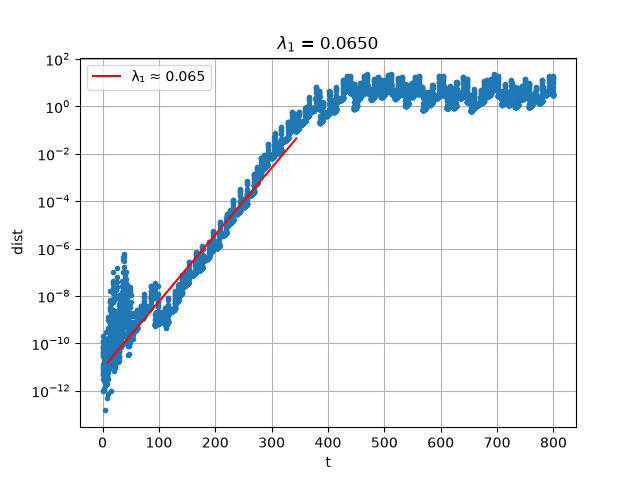

In [11]:
    # Lyapunov no caso caótico de c=11.0


# É preciso diminuir rtol e atol para a ordem de precisão da máquina, visto que a distância inicial de 1e-12
# se aproxima dessa escala.     
OPCOES = dict(dense_output=True, method='DOP853', rtol=3e-14, atol=1e-14)


# Foi feita uma simulação com um tSpan consideravelmente maior do que nos outros casos, pois, como é visivel pelo expoente obtido, o sistema é "fracamente caótico"
Sol = simularosslerIVP(a =0.1, b=0.1, c=11.0, tTransiente=1_000, tSpan=800, nMax=500, r0=r0, options=OPCOES, dist0=1e-12)
r = Sol[2].y
rlinha = Sol[3].y

t0, t1 = Sol[2].t, Sol[3].t

    # novamente a interpolação para ajustar o número de pontos
tmin = max(t0[0], t1[0])
tmax = min(t0[-1], t1[-1])
t = np.linspace(tmin, tmax, 10_001)

r      = CubicSpline(t0, r,      axis=1)(t)
rlinha = CubicSpline(t1, rlinha, axis=1)(t)

dist = np.sqrt(np.sum((r - rlinha)**2, axis = 0))

    # Região confiavelmente linear para se obter o expoente do gráfico
mask = (dist > 1e-9) & (dist < 1e-1)
coef = np.polyfit(t[mask], np.log(dist[mask]), 1)
lambda_1 = coef[0]
print(f'lambda_1 ≈ {lambda_1:.4f}')

plt.close( 'all' )
plt.figure()
plt.plot( t,dist, '.' )
plt.xlabel( 't' )
plt.ylabel( 'dist' )
plt.yscale( 'log' )
    #plt.xlim( [0, 30] )
plt.grid()
plt.plot(t[mask], np.exp(np.polyval(coef, t[mask])), 'r-', label=f'λ₁ ≈ {lambda_1:.3f}')
plt.legend()
plt.title(f'$\lambda_1$ = {lambda_1:.4f}')
plt.show()
